In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from linearmodels.panel import PanelOLS, compare
import numpy as np

In [2]:
INDEX_COLS = ['alpha', 'beta', 'gamma']
QUARTER_PANEL_PATH = '../data/checkpoints/ready/panel_q.csv'
BIANNUAL_PANEL_PATH = '../data/checkpoints/ready/panel_h.csv'
FULL_PANEL_PATH = '../data/checkpoints/ready/panel_full.csv'

GRAPHS_PATH = '../temp/graphics/graphs/'
TABLES_PATH = '../temp/graphics/tables/'
EVENT_STUDY_FOLDER = 'event_studies/'


REFERENCE_QUINTILE = 1

quintiles = [1,2,3,4,5]
quintiles.remove(REFERENCE_QUINTILE)

DV_COL = 'Y_SHARE'
DV_NAME = 'Entry-Level Workers Share'

In [3]:
panel_q = pd.read_csv(QUARTER_PANEL_PATH)
panel_h = pd.read_csv(BIANNUAL_PANEL_PATH)
panel_full = pd.read_csv(FULL_PANEL_PATH)

In [4]:
print(panel_q.columns)

Index(['OCC', 'QUARTER', 'N', 'np', 'alpha', 'beta', 'gamma', 'Y_SHARE',
       'arcsinh_np', 'arcsinh_N', 'alpha_quintile', 'alpha_quintile_1',
       'alpha_quintile_2', 'alpha_quintile_3', 'alpha_quintile_4',
       'alpha_quintile_5', 'beta_quintile', 'beta_quintile_1',
       'beta_quintile_2', 'beta_quintile_3', 'beta_quintile_4',
       'beta_quintile_5', 'gamma_quintile', 'gamma_quintile_1',
       'gamma_quintile_2', 'gamma_quintile_3', 'gamma_quintile_4',
       'gamma_quintile_5'],
      dtype='str')


EVENT STUDY FORMULA: Y_SHARE ~ beta_quintile_2:Q("QUARTER_-4") + beta_quintile_2:Q("QUARTER_-3") + beta_quintile_2:Q("QUARTER_-2") + beta_quintile_2:Q("QUARTER_0") + beta_quintile_2:Q("QUARTER_1") + beta_quintile_2:Q("QUARTER_2") + beta_quintile_2:Q("QUARTER_3") + beta_quintile_2:Q("QUARTER_4") + beta_quintile_2:Q("QUARTER_5") + beta_quintile_2:Q("QUARTER_6") + beta_quintile_2:Q("QUARTER_7") + beta_quintile_2:Q("QUARTER_8") + beta_quintile_2:Q("QUARTER_9") + beta_quintile_2:Q("QUARTER_10") + beta_quintile_2:Q("QUARTER_12") + beta_quintile_2:Q("QUARTER_13") + EntityEffects + TimeEffects ------------------------------
EVENT STUDY FORMULA: Y_SHARE ~ beta_quintile_3:Q("QUARTER_-4") + beta_quintile_3:Q("QUARTER_-3") + beta_quintile_3:Q("QUARTER_-2") + beta_quintile_3:Q("QUARTER_0") + beta_quintile_3:Q("QUARTER_1") + beta_quintile_3:Q("QUARTER_2") + beta_quintile_3:Q("QUARTER_3") + beta_quintile_3:Q("QUARTER_4") + beta_quintile_3:Q("QUARTER_5") + beta_quintile_3:Q("QUARTER_6") + beta_quintil

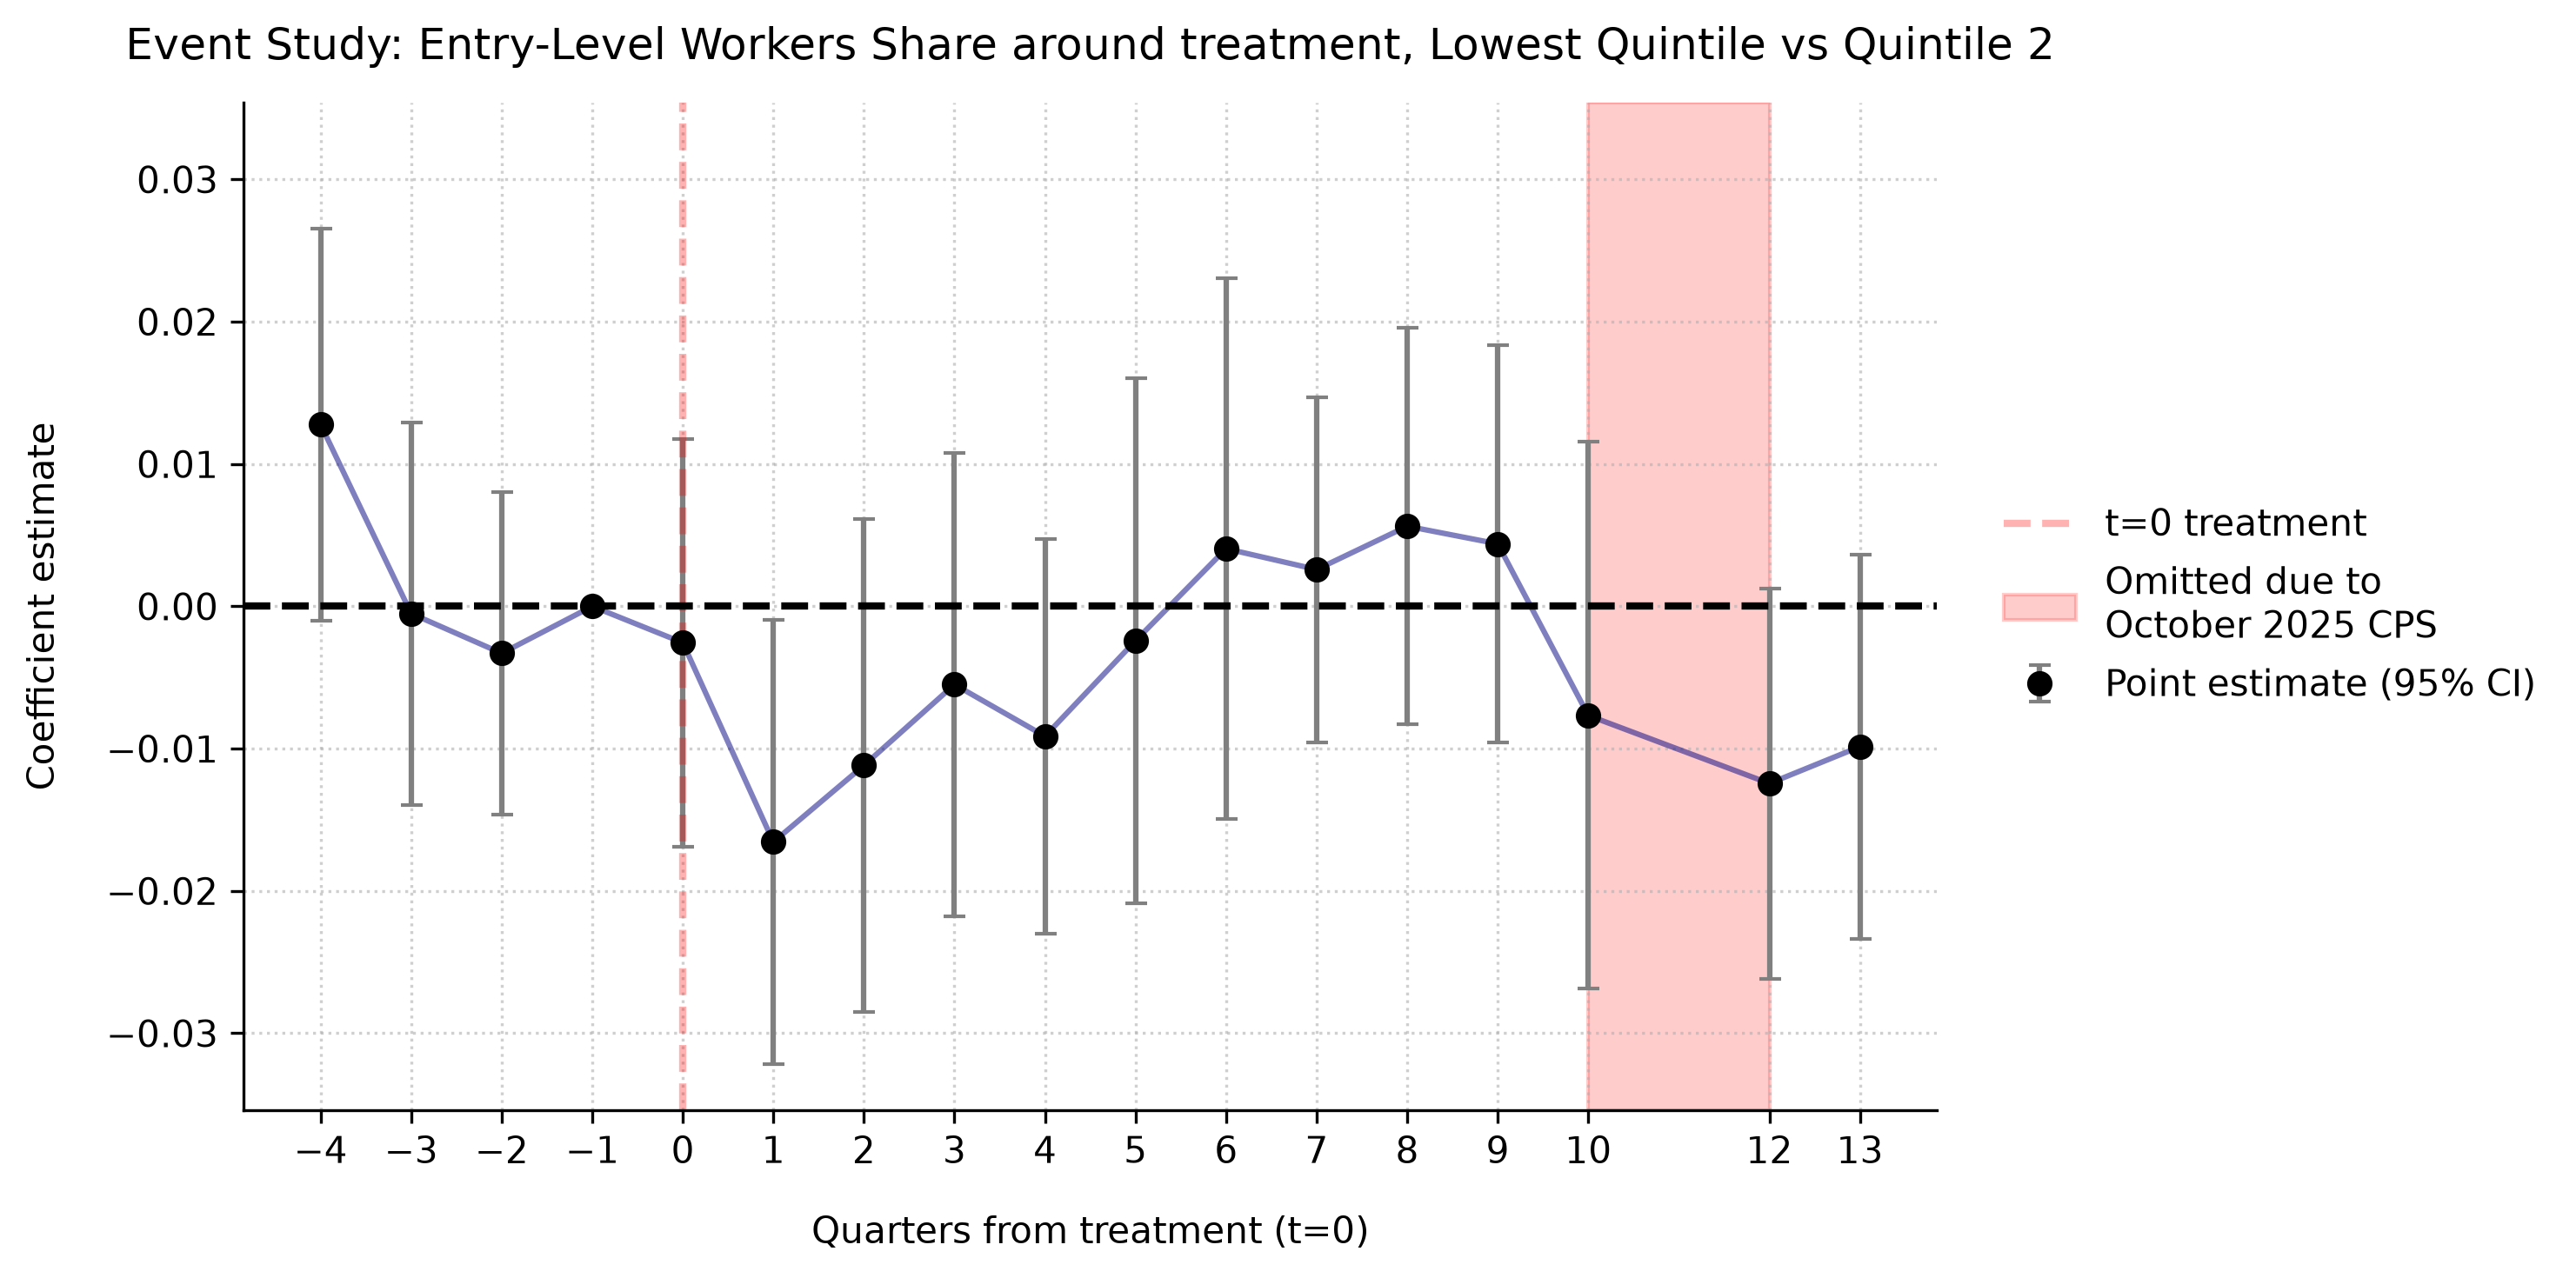

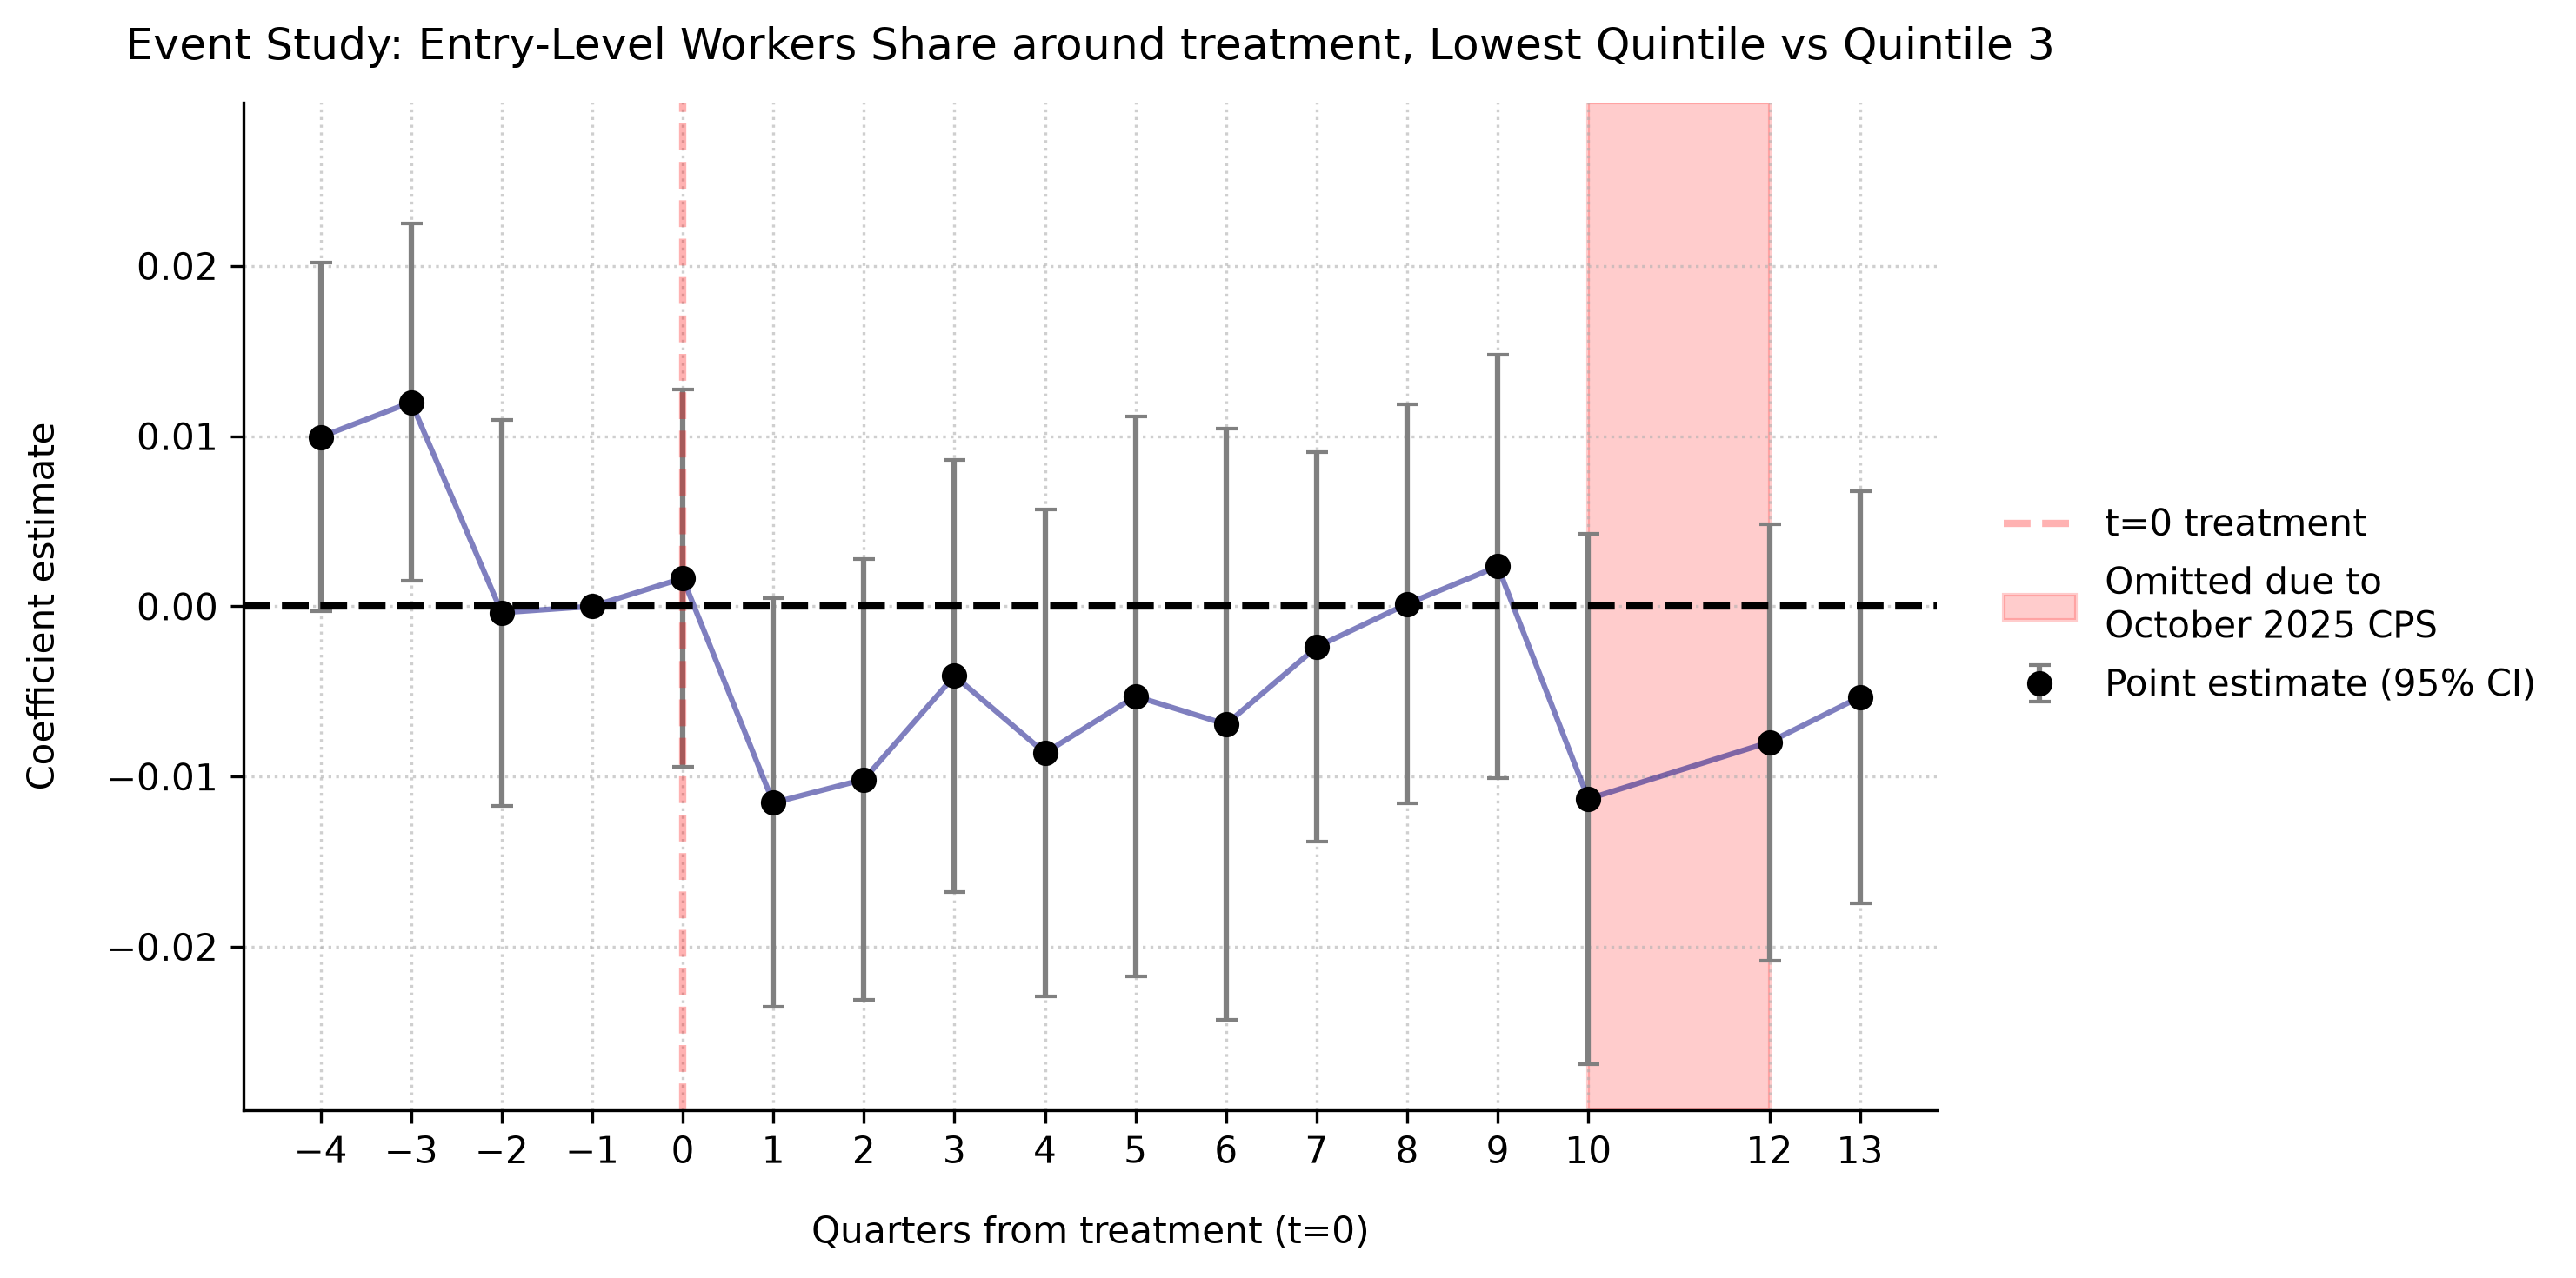

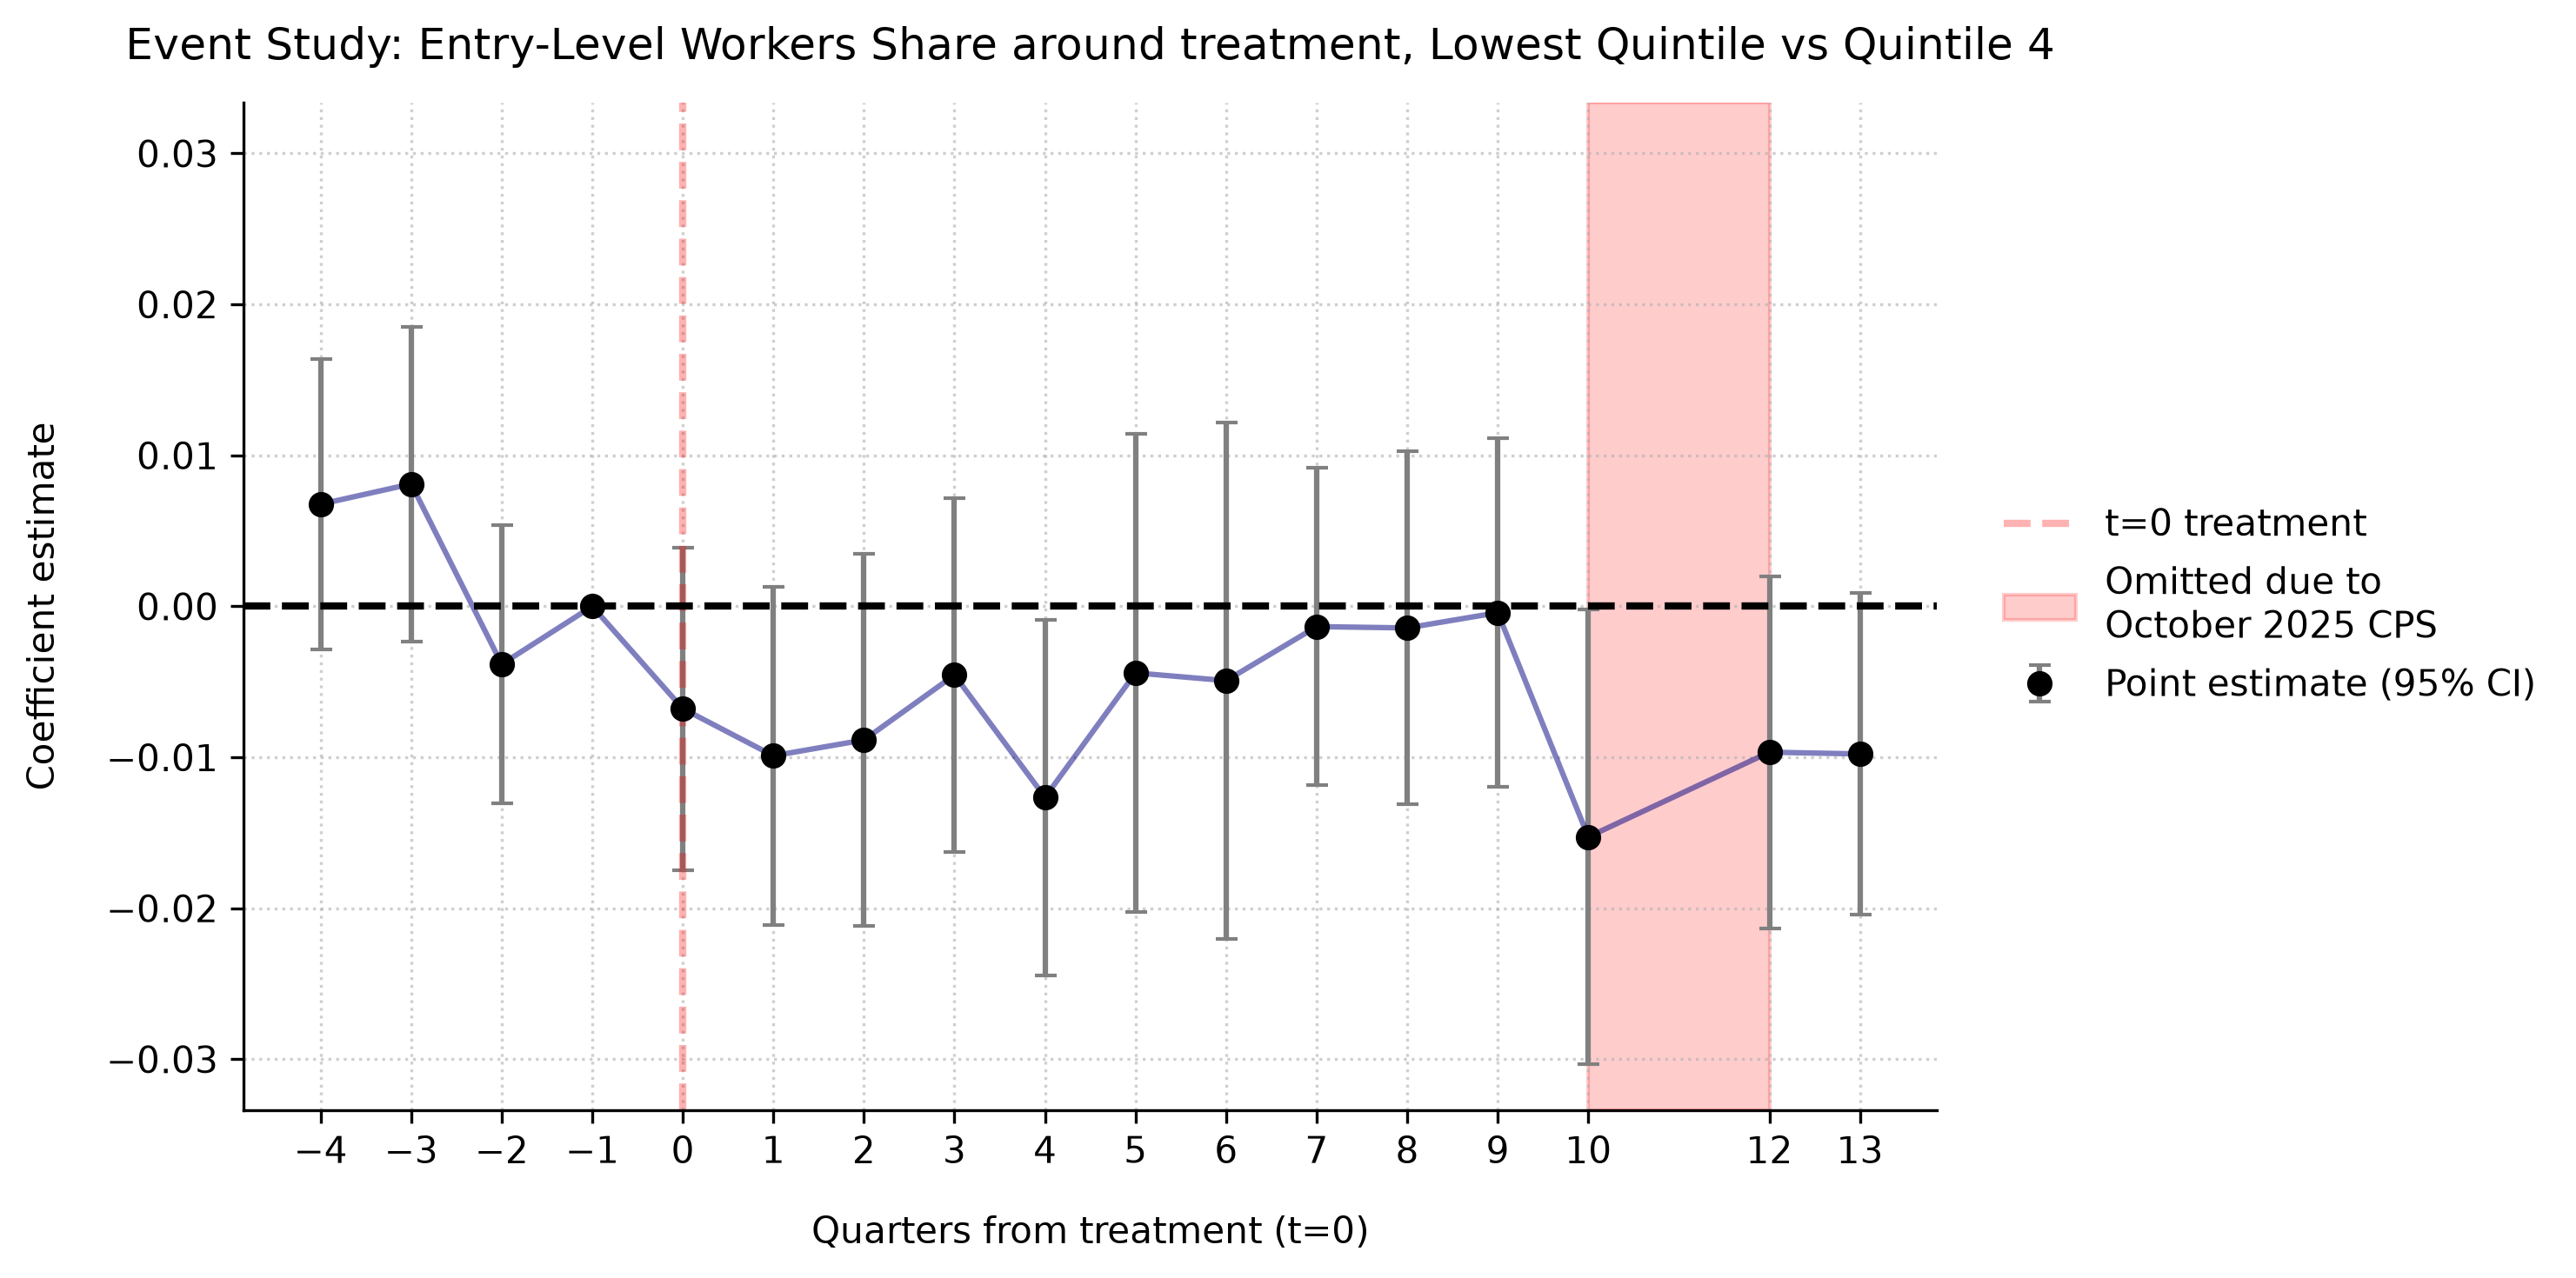

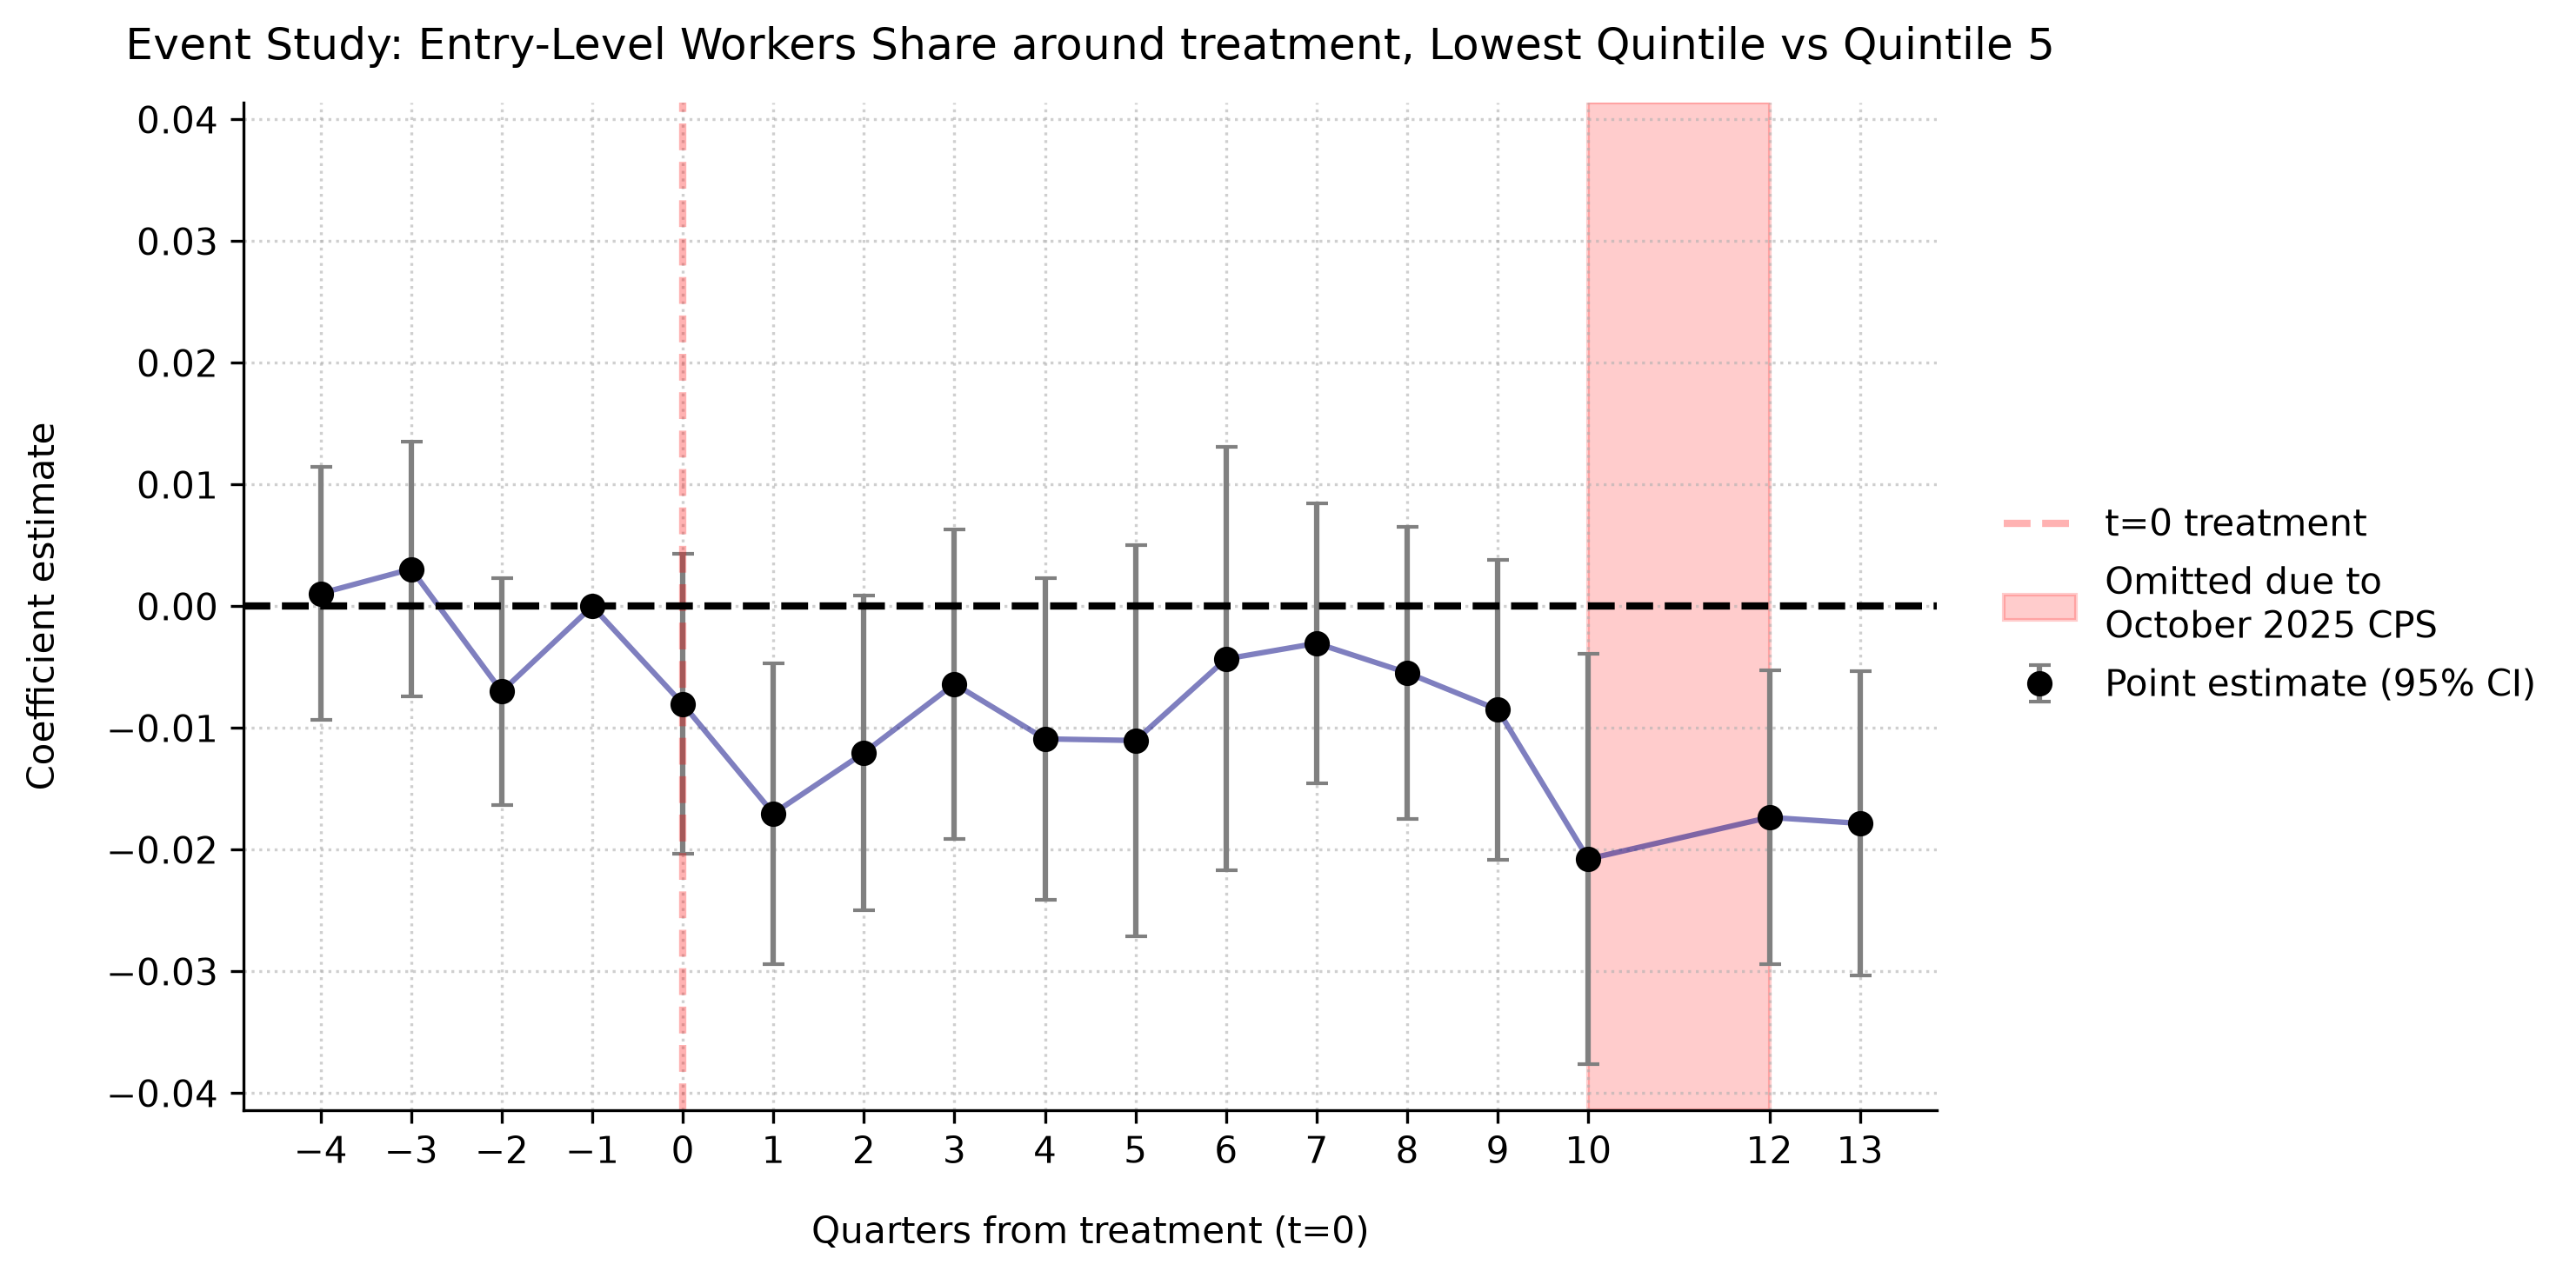

In [6]:
# Event study

for quintile in quintiles:
    df_event = panel_q.set_index(['OCC', 'QUARTER'], drop=False)
    
    # Filter out unselected quintiles
    df_event = df_event[df_event['beta_quintile'].isin([REFERENCE_QUINTILE, quintile])]

    # Get Quarter Dummies 
    df_event = pd.get_dummies(df_event, columns=['QUARTER'], drop_first=False, dtype=int)

    # Drop the reference period and create list of dummies
    df_event = df_event.drop(columns=['QUARTER_-1'])
    quarter_dummies = [c for c in df_event.columns if c.startswith('QUARTER_')]

    # Create interaction terms and event study formula
    interaction_terms = ' + '.join([f'beta_quintile_{quintile}:Q("{d}")' for d in quarter_dummies])
    formula = f"{DV_COL} ~ {interaction_terms} + EntityEffects + TimeEffects"
    print(f"EVENT STUDY FORMULA: {formula} {'-'*30}")
    
    # Event study in PANELOLS
    event_study_mod = PanelOLS.from_formula(formula, data=df_event, weights=df_event['N'])
    event_study_res = event_study_mod.fit(cov_type='clustered', cluster_entity=True)
    
    # Save output to tex file
    dv_slug = DV_NAME.replace(' ', '_')
    with open(f"{TABLES_PATH}{EVENT_STUDY_FOLDER}{dv_slug}_Quintile{quintile}_reg.tex", "w") as f:
        f.write(event_study_res.summary.as_latex())

    df_res = pd.DataFrame({
        'coef': event_study_res.params,
        'lower': event_study_res.conf_int()['lower'],
        'upper': event_study_res.conf_int()['upper']
    })
    
    # Reorganize to reinsert omitted variable
    df_res['quarter'] = df_res['quarter'] = (
        df_res.index
        .str.extract(r"QUARTER_(-?\d+)", expand=False)
        .astype(int)
    )
    baseline = pd.DataFrame({'coef': 0.0, 'lower': 0.0, 'upper': 0.0, 'quarter': -1}, index=[-1])
    df_res = pd.concat([df_res, baseline]).sort_values('quarter').reset_index(drop=True)
    
    # Create graph
    fig, ax = plt.subplots(figsize=(10, 5), dpi=300)

    yerr_lower = df_res['coef'] - df_res['lower']
    yerr_upper = df_res['upper'] - df_res['coef']

    ax.errorbar(
        x=df_res['quarter'],
        y=df_res['coef'],
        yerr=np.asanyarray([yerr_lower, yerr_upper]),
        fmt='o',
        color='black',
        ecolor='gray',
        capsize=3,             
        linestyle='None',
        label='Point estimate (95% CI)'
    )

    ax.plot(df_res['quarter'], df_res['coef'], color='navy', alpha=0.5)

    ax.grid(True, linestyle=':', alpha=0.6)

    ax.axvline(x=0, color='r', linestyle='--', linewidth=2, alpha=0.3, label="t=0 treatment")
    ax.axhline(y=0, color='black', linestyle='--', linewidth=2)
    ax.set_xticks(sorted(df_res['quarter'].unique()))

    ax.set_xlabel('Quarters from treatment (t=0)', labelpad=12)
    ax.set_ylabel('Coefficient estimate', labelpad=12)
    ax.set_title(f'Event Study: {DV_NAME} around treatment, Lowest Quintile vs Quintile {quintile}', pad=12)

    y_max = max(df_res['upper'].abs().max(), df_res['lower'].abs().max())
    margin = y_max * 0.1  # 10% padding, adjust to taste
    ax.set_ylim(-(y_max + margin), y_max + margin)
    ax.axvspan(10, 12, color='r', alpha = 0.2, label= "Omitted due to\nOctober 2025 CPS")

    ax.spines[['top', 'right']].set_visible(False)
    ax.legend(frameon=False, loc='center left', bbox_to_anchor=(1.02, 0.5))

    plt.tight_layout()
    
    # Save graph
    fig.savefig(f"{GRAPHS_PATH}{EVENT_STUDY_FOLDER}{dv_slug}_Quintile{quintile}_EventStudy.png", dpi=300, bbox_inches='tight')

In [7]:
### Setup for DiD and placebo tests
placebo_treatments = [-3,-2]
placebo_results = {}

for quintile in quintiles:
    # Drop post-treatment and non used quintiles
    df_placebo = panel_q.set_index(['OCC', 'QUARTER'], drop=False)
    df_placebo = df_placebo[(df_placebo['QUARTER'] < 0)]
    df_placebo = df_placebo[df_placebo['beta_quintile'].isin([REFERENCE_QUINTILE, quintile])]

    for treatment_date in placebo_treatments:
        df_placebo['POST'] = (df_placebo['QUARTER'] >= treatment_date).astype(int)
        placebo_formula = f"{DV_COL} ~ POST:beta_quintile_{quintile} + EntityEffects + TimeEffects"
        placebo_mod = PanelOLS.from_formula(placebo_formula, data=df_placebo, weights=df_placebo['N'])
        res_placebo = placebo_mod.fit(cov_type='clustered', cluster_entity=True)
        
        # Key each result by quintile + placebo date so it's identifiable in the table
        placebo_results[f'Q{quintile}, t0={treatment_date}'] = res_placebo

# Build the comparison table
placebo_comparison = compare(placebo_results,  stars=True)
print(placebo_comparison)

# Save to LaTeX for reference
with open(f"{TABLES_PATH}placebo_comparison.tex", "w") as f:
    f.write(placebo_comparison.summary.as_latex())


                                                            Model Comparison                                                            
                             Q2, t0=-3     Q2, t0=-2     Q3, t0=-3     Q3, t0=-2     Q4, t0=-3     Q4, t0=-2     Q5, t0=-3     Q5, t0=-2
----------------------------------------------------------------------------------------------------------------------------------------
Dep. Variable                  Y_SHARE       Y_SHARE       Y_SHARE       Y_SHARE       Y_SHARE       Y_SHARE       Y_SHARE       Y_SHARE
Estimator                     PanelOLS      PanelOLS      PanelOLS      PanelOLS      PanelOLS      PanelOLS      PanelOLS      PanelOLS
No. Observations                   548           548           552           552           556           556           580           580
Cov. Est.                    Clustered     Clustered     Clustered     Clustered     Clustered     Clustered     Clustered     Clustered
R-squared                       0.0171   

In [63]:
### Linear trend test

for quintile in quintiles:
    df_ltrend = panel_q.set_index(['OCC', 'QUARTER'], drop=False)
    df_ltrend = df_ltrend[df_ltrend['QUARTER'] < 0]
    df_ltrend = df_ltrend[df_ltrend['beta_quintile'].isin([REFERENCE_QUINTILE, quintile])]

    ltrend_formula = f"{DV_COL} ~ QUARTER:beta_quintile_{quintile} + EntityEffects + TimeEffects"
    ltrend_mod = PanelOLS.from_formula(ltrend_formula, data=df_ltrend, weights=df_ltrend['N'])
    res_ltrend = ltrend_mod.fit(cov_type='clustered', cluster_entity=True)
    print(res_ltrend.summary)


                          PanelOLS Estimation Summary                           
Dep. Variable:                Y_SHARE   R-squared:                        0.0063
Estimator:                   PanelOLS   R-squared (Between):              0.0348
No. Observations:                 576   R-squared (Within):              -0.0119
Date:                Thu, Jul 30 2026   R-squared (Overall):              0.0342
Time:                        17:38:26   Log-likelihood                    1338.2
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      2.6953
Entities:                         144   P-value                           0.1014
Avg Obs:                       4.0000   Distribution:                   F(1,428)
Min Obs:                       4.0000                                           
Max Obs:                       4.0000   F-statistic (robust):             1.7560
                            